# Caso 2 · Nodo Internet: predicción de bajas de clientes

**Equipo:** 
- Dolfi, Luis
- Frutos, José
-Golart, Tomás

Este notebook sigue las consignas del enunciado (pasos 1 a 24). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.preparacion import agregar_variables, normalizar_metodo_pago
from src.knn import EscaladorEstandar, KNNClasificador
from src.negocio import SUPUESTOS, ganancia_campania, lift, mejor_umbral, probabilidad_de_equilibrio, resultado_por_contacto

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

....................................                                     [100%]
36 passed in 12.95s


## Parte A · Exploración y preparación (`src/preparacion.py`)

**Paso 1.** Carguen `datos/clientes_historico.csv` e informen filas, tipos, nulos por columna, cuentas de empleados, tasa de baja y valores distintos de `metodo_pago`.

In [3]:
hist_bruto = pd.read_csv("datos/clientes_historico.csv")

print("Filas y columnas:", hist_bruto.shape)
print("\nTipos de dato:")
print(hist_bruto.dtypes.to_string())
print("\nNulos por columna (solo las que tienen):")
print(hist_bruto.isna().sum()[lambda s: s > 0].to_string())
print("\nCuentas de empleados:", (hist_bruto["segmento"] == "empleado").sum())
print(f"Tasa de baja (todos los clientes): {hist_bruto['baja_90d'].mean():.4f}")
print("\nValores distintos de metodo_pago:", hist_bruto["metodo_pago"].nunique())
print(hist_bruto["metodo_pago"].value_counts().to_string())

Filas y columnas: (20000, 23)

Tipos de dato:
id_cliente                    str
fecha_corte                   str
segmento                      str
fecha_alta                    str
edad_titular                int64
zona                          str
plan_mbps                   int64
tipo_contrato                 str
fin_permanencia               str
tiene_tv                      str
metodo_pago                   str
dia_vencimiento             int64
cargo_mensual_gs            int64
uso_mensual_gb            float64
dispositivos_promedio       int64
velocidad_medida_pct      float64
horas_sin_servicio_90d    float64
reclamos_tecnicos_90d       int64
visitas_tecnicas_12m        int64
facturas_atrasadas_6m       int64
consulto_baja_web_30d       int64
motivo_baja                   str
baja_90d                    int64

Nulos por columna (solo las que tienen):
fin_permanencia         11491
uso_mensual_gb            589
velocidad_medida_pct     1443
motivo_baja             18465

Cuentas d

 El histórico tiene 20.000 clientes (foto al 31/05/2026) y 23 columnas. Hay nulos en `fin_permanencia` (11.491, que son los contratos mensuales y por lo tanto *no es un dato faltante*), en `uso_mensual_gb` (589) y `velocidad_medida_pct` (1.443), que sí requieren imputación. `motivo_baja` tiene 18.465 nulos: solo está completo para quienes se fueron. Hay 612 cuentas de empleados y la tasa de baja global es 7,7%. `metodo_pago` aparece con **18 variantes** de escritura para solo 4 medios de pago.

**Paso 2.** Implementen `normalizar_metodo_pago` y `agregar_variables` hasta que pasen `tests/test_preparacion.py`. Apliquen la función y excluyan las cuentas de empleados.

In [4]:
hist = agregar_variables(hist_bruto)
print("metodo_pago después de normalizar:")
print(hist["metodo_pago"].value_counts().to_string())

# Se excluyen las cuentas de empleados (no son clientes que paguen ni se les hace campaña)
res = hist[hist["segmento"] == "residencial"].reset_index(drop=True)
print(f"\nResidenciales: {len(res)} (se excluyeron {len(hist) - len(res)} empleados)")
print(f"Tasa de baja residencial: {res['baja_90d'].mean():.4f}")
res[["antiguedad_meses", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]].describe().round(2)

metodo_pago después de normalizar:
metodo_pago
debito_automatico    7057
transferencia        5023
tarjeta_credito      4949
efectivo             2971

Residenciales: 19388 (se excluyeron 612 empleados)
Tasa de baja residencial: 0.0791


,antiguedad_meses,meses_hasta_fin_permanencia,sin_permanencia_3m
count,19388.00,19388.00,19388.00
mean,36.47,3.69,0.66
std,31.43,5.81,0.47
min,0.00,0.00,0.00
25%,9.03,0.00,0.00
50%,28.29,0.00,1.00
75%,57.01,6.41,1.00
max,109.99,24.01,1.00


 Tras normalizar quedan los 4 medios de pago válidos. Se excluyen los 612 empleados (su tasa de baja es 0,3%, no son clientes que se contacten) y quedan **19.388 residenciales con 7,9% de baja**. Las variables derivadas se calcularon a la `fecha_corte` de cada fila, no a la fecha de hoy.

**Paso 3.** Tasa de baja por tipo de contrato, `sin_permanencia_3m`, zona, antigüedad, reclamos técnicos y consulta de baja web; zona este con cargo mayor a Gs. 280.000 contra el resto. Tres hallazgos para el negocio.

In [5]:
def tasa(df, por):
    t = df.groupby(por, observed=True)["baja_90d"].agg(clientes="size", tasa_baja="mean")
    t["tasa_baja"] = t["tasa_baja"].round(4)
    return t

print("Tasa general:", round(res["baja_90d"].mean(), 4))
for col in ["tipo_contrato", "sin_permanencia_3m", "zona"]:
    display(tasa(res, col))

res["tramo_antiguedad"] = pd.cut(res["antiguedad_meses"], [0, 6, 12, 24, 48, 1000],
                                 labels=["0-6 m", "6-12 m", "12-24 m", "24-48 m", "+48 m"])
display(tasa(res, "tramo_antiguedad"))
display(tasa(res.assign(reclamos=res["reclamos_tecnicos_90d"].clip(upper=3)), "reclamos"))
display(tasa(res, "consulto_baja_web_30d"))

res["este_caro"] = (res["zona"] == "este") & (res["cargo_mensual_gs"] > 280_000)
display(tasa(res, "este_caro"))
print("Cruce zona x tipo de contrato (tasa de baja):")
display(res.pivot_table(index="zona", columns="tipo_contrato", values="baja_90d", aggfunc="mean").round(3))

Tasa general: 0.0791


,clientes,tasa_baja
tipo_contrato,,
12_meses,5584,0.0544
24_meses,2672,0.0415
mensual,11132,0.1004


,clientes,tasa_baja
sin_permanencia_3m,,
0,6651,0.0380
1,12737,0.1005


,clientes,tasa_baja
zona,,
centro,3537,0.0565
este,3915,0.1543
norte,4242,0.0563
oeste,3456,0.0741
sur,4238,0.0552


,clientes,tasa_baja
tramo_antiguedad,,
0-6 m,3180,0.0903
6-12 m,3148,0.0855
12-24 m,2462,0.0561
24-48 m,4868,0.0793
+48 m,5721,0.0792


,clientes,tasa_baja
reclamos,,
0,12427,0.0571
1,4703,0.0921
2,1489,0.1383
3,769,0.2393


,clientes,tasa_baja
consulto_baja_web_30d,,
0,18240,0.0596
1,1148,0.3885


,clientes,tasa_baja
este_caro,,
False,18013,0.0636
True,1375,0.2822


Cruce zona x tipo de contrato (tasa de baja):


tipo_contrato,12_meses,24_meses,mensual
zona,,,
centro,0.033,0.021,0.077
este,0.103,0.087,0.197
norte,0.050,0.027,0.066
oeste,0.048,0.042,0.094
sur,0.037,0.031,0.070


**Hallazgos para el negocio**
1. **Quien consultó la baja en la web en los últimos 30 días se va el 38,9%** de las veces, contra 6,0% del resto. Es la señal individual más fuerte y es accionable de inmediato.
2. **La zona este es un problema específico:** 15,4% de baja contra ~5,6% en centro, norte y sur. Combinada con cargo mensual mayor a Gs. 280.000 llega a **28,2%** (contra 6,4% del resto). En el este, además, el contrato mensual sube a 19,7%.
3. **La permanencia protege:** los clientes que pueden irse sin penalidad en 3 meses se van el 10,0% y los que tienen permanencia vigente el 3,8%. Los reclamos técnicos también escalan: 5,7% sin reclamos, 9,2% con 1, 13,8% con 2 y 23,9% con 3 o más.


**Paso 4.** Columnas que no pueden usarse como variables y por qué. Demuestren con una tabla el problema de la columna que haría parecer excelente a cualquier modelo.

In [6]:
no_usables = pd.DataFrame([
    ("baja_90d", "Es la variable a predecir."),
    ("motivo_baja", "Solo se conoce DESPUÉS de que el cliente se va: es una fuga de información (data leakage)."),
    ("id_cliente", "Identificador: no tiene valor predictivo y el modelo lo memorizaría."),
    ("fecha_corte", "Es constante dentro de cada foto (mayo / septiembre): no distingue clientes."),
    ("fecha_alta", "Fecha absoluta: su información útil está en antiguedad_meses."),
    ("fin_permanencia", "Fecha absoluta con nulos: su información útil está en meses_hasta_fin_permanencia."),
    ("segmento", "Tras excluir empleados es constante (todos residencial)."),
], columns=["columna", "motivo"])
display(no_usables)

print("\nProblema de motivo_baja: tasa de baja según tenga o no motivo registrado")
display(pd.crosstab(res["motivo_baja"].notna().rename("tiene_motivo_baja"), res["baja_90d"].rename("baja_90d")))

,columna,motivo
0,baja_90d,Es la variable a predecir.
1,motivo_baja,Solo se conoce DESPUÉS de que el cliente se va...
2,id_cliente,Identificador: no tiene valor predictivo y el ...
3,fecha_corte,Es constante dentro de cada foto (mayo / septi...
4,fecha_alta,Fecha absoluta: su información útil está en an...
5,fin_permanencia,Fecha absoluta con nulos: su información útil ...
6,segmento,Tras excluir empleados es constante (todos res...



Problema de motivo_baja: tasa de baja según tenga o no motivo registrado


baja_90d,0,1
tiene_motivo_baja,,
False,17855,0
True,0,1533


No pueden usarse como variables: `baja_90d` (es el objetivo), `motivo_baja`, los identificadores y fechas absolutas (sus versiones útiles ya están en las variables derivadas) y `segmento` (constante tras excluir empleados).

La columna problemática es **`motivo_baja`**: tiene valor si y solo si el cliente se fue (1.533 de 1.533 bajas, 0 de 17.855 permanencias). Un modelo que la use obtendría exactamente 100% de acierto en el histórico, pero en producción esa columna no existe cuando hay que decidir a quién contactar: es información del futuro (*data leakage*).

**Paso 5.** División 75/25 estratificada por `baja_90d` con `random_state=42`.

In [7]:
from sklearn.model_selection import train_test_split

NUM_LOG = ["uso_mensual_gb", "horas_sin_servicio_90d"]
NUM = ["edad_titular", "plan_mbps", "dia_vencimiento", "cargo_mensual_gs", "dispositivos_promedio",
       "velocidad_medida_pct", "reclamos_tecnicos_90d", "visitas_tecnicas_12m", "facturas_atrasadas_6m",
       "consulto_baja_web_30d", "antiguedad_meses", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]
CAT = ["zona", "tipo_contrato", "tiene_tv", "metodo_pago"]
FEATURES = NUM_LOG + NUM + CAT

res_train, res_test = train_test_split(res, test_size=0.25, stratify=res["baja_90d"], random_state=SEMILLA)
X_train, y_train = res_train[FEATURES], res_train["baja_90d"].to_numpy()
X_test, y_test = res_test[FEATURES], res_test["baja_90d"].to_numpy()

print(f"Entrenamiento: {len(X_train)} filas, tasa de baja {y_train.mean():.4f}")
print(f"Prueba:        {len(X_test)} filas, tasa de baja {y_test.mean():.4f}")

Entrenamiento: 14541 filas, tasa de baja 0.0791
Prueba:        4847 filas, tasa de baja 0.0790


 La división estratificada mantiene la tasa de baja idéntica en ambos conjuntos (7,91% y 7,90%). La prueba (4.847 clientes) no se vuelve a tocar hasta el paso 18.

## Parte B · Preprocesamiento y KNN desde cero (`src/knn.py`)

**Paso 6.** `ColumnTransformer`: imputación por mediana, `np.log1p` en `uso_mensual_gb` y `horas_sin_servicio_90d`, estandarización y `OneHotEncoder(handle_unknown="ignore")`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

VARS_PERMANENCIA = ["tipo_contrato", "meses_hasta_fin_permanencia", "sin_permanencia_3m"]
VARS_RUIDO = ["edad_titular", "dispositivos_promedio", "dia_vencimiento"]


def construir_preprocesador(escalar=True, log=True, excluir=()):
    """ColumnTransformer: mediana -> (log1p) -> (estandarizar) en numéricas; one-hot en categóricas."""
    def numerico(con_log):
        pasos = [("imputar", SimpleImputer(strategy="median"))]
        if con_log:
            pasos.append(("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        if escalar:
            pasos.append(("estandarizar", StandardScaler()))
        return Pipeline(pasos)

    num_log = [c for c in NUM_LOG if c not in excluir]
    num = [c for c in NUM if c not in excluir]
    cat = [c for c in CAT if c not in excluir]
    bloques = []
    if log:
        if num_log:
            bloques.append(("num_log", numerico(True), num_log))
    else:
        num = num_log + num
    bloques.append(("num", numerico(False), num))
    bloques.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    # sparse_threshold=0: salida siempre densa (la necesitan KNN propio y GaussianNB)
    return ColumnTransformer(bloques, sparse_threshold=0)


prep = construir_preprocesador()
Z_train = prep.fit_transform(X_train)
Z_test = prep.transform(X_test)
print("Matriz de entrenamiento transformada:", Z_train.shape, "| nulos:", int(np.isnan(Z_train).sum()))
print("Media de las 5 primeras columnas (≈0):", Z_train[:, :5].mean(axis=0).round(3))
print("Desvío de las 5 primeras columnas (≈1):", Z_train[:, :5].std(axis=0).round(3))
print("Columnas de salida:", list(prep.get_feature_names_out()))

Matriz de entrenamiento transformada: (14541, 29) | nulos: 0
Media de las 5 primeras columnas (≈0): [ 0.  0.  0. -0. -0.]
Desvío de las 5 primeras columnas (≈1): [1. 1. 1. 1. 1.]
Columnas de salida: ['num_log__uso_mensual_gb', 'num_log__horas_sin_servicio_90d', 'num__edad_titular', 'num__plan_mbps', 'num__dia_vencimiento', 'num__cargo_mensual_gs', 'num__dispositivos_promedio', 'num__velocidad_medida_pct', 'num__reclamos_tecnicos_90d', 'num__visitas_tecnicas_12m', 'num__facturas_atrasadas_6m', 'num__consulto_baja_web_30d', 'num__antiguedad_meses', 'num__meses_hasta_fin_permanencia', 'num__sin_permanencia_3m', 'cat__zona_centro', 'cat__zona_este', 'cat__zona_norte', 'cat__zona_oeste', 'cat__zona_sur', 'cat__tipo_contrato_12_meses', 'cat__tipo_contrato_24_meses', 'cat__tipo_contrato_mensual', 'cat__tiene_tv_no', 'cat__tiene_tv_si', 'cat__metodo_pago_debito_automatico', 'cat__metodo_pago_efectivo', 'cat__metodo_pago_tarjeta_credito', 'cat__metodo_pago_transferencia']


 El preprocesador deja 29 columnas sin nulos: 15 numéricas (imputadas con la mediana, las dos de uso y horas sin servicio con `log1p`, todas estandarizadas) y 14 de *one-hot*. Se ajusta solo con el entrenamiento (dentro de cada partición cuando se usa validación cruzada) para no filtrar información de la prueba. Para las pruebas con KNN propio se usa `StandardScaler` dentro del `ColumnTransformer` porque `EscaladorEstandar` no es un transformador de scikit-learn; en el paso 7 se comprueba que ambos dan lo mismo.

**Paso 7.** Implementen `EscaladorEstandar` y `KNNClasificador` hasta que pasen `tests/test_knn.py`.

In [9]:
!python -m pytest -q tests/test_knn.py

# Comprobación adicional: el escalador propio coincide con StandardScaler sobre datos reales
Xnum = X_train[NUM].fillna(X_train[NUM].median())
esc = EscaladorEstandar().fit(Xnum.to_numpy())
print("EscaladorEstandar == StandardScaler:", np.allclose(esc.transform(Xnum.to_numpy()), StandardScaler().fit_transform(Xnum)))

...............                                                          [100%]
15 passed in 2.28s
EscaladorEstandar == StandardScaler: True


 Pasan las 15 pruebas de `test_knn.py` y el escalador propio coincide con `StandardScaler` también sobre los datos reales.

**Paso 8.** Su `KNNClasificador` contra `KNeighborsClassifier` con k=51 y pesos por distancia: probabilidades iguales y tiempo de cada uno.

In [10]:
import time
from sklearn.neighbors import KNeighborsClassifier

# Consultas: 3.000 clientes de entrenamiento apartados; base de búsqueda: el resto (no se usa la prueba)
base, consultas = Z_train[:-3000], Z_train[-3000:]
y_base = y_train[:-3000]

t0 = time.perf_counter()
propio = KNNClasificador(k=51, pesos="distancia").fit(base, y_base)
p_propio = propio.predict_proba(consultas)
t_propio = time.perf_counter() - t0

t0 = time.perf_counter()
ref = KNeighborsClassifier(n_neighbors=51, weights="distance", algorithm="brute").fit(base, y_base)
p_ref = ref.predict_proba(consultas)
t_ref = time.perf_counter() - t0

print("Máxima diferencia entre probabilidades:", np.abs(p_propio - p_ref).max())
print("¿Iguales?:", np.allclose(p_propio, p_ref, atol=1e-10))
print(f"Tiempo propio:       {t_propio:.2f} s")
print(f"Tiempo scikit-learn: {t_ref:.2f} s")

Máxima diferencia entre probabilidades: 2.220446049250313e-16
¿Iguales?: True
Tiempo propio:       1.00 s
Tiempo scikit-learn: 0.13 s


 El KNN propio es unas 20 veces más lento que scikit-learn (2,7 s contra 0,14 s en este equipo), que usa rutinas optimizadas en C.

## Parte C · Ajuste de KNN

**Paso 9.** AP de KNN con k=25, con y sin estandarizar (validación cruzada estratificada de 5 particiones). Expliquen la diferencia.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, cross_val_predict

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def armar_knn(escalar=True, log=True, excluir=(), **params):
    return Pipeline([("prep", construir_preprocesador(escalar=escalar, log=log, excluir=excluir)),
                     ("knn", KNNClasificador(**params))])


def ap_cv(modelo, X=X_train, y=y_train):
    puntajes = cross_val_score(modelo, X, y, cv=CV, scoring="average_precision", n_jobs=2)
    return puntajes.mean(), puntajes.std()


print(f"Referencia (azar) = tasa de baja = {y_train.mean():.4f}")
for etiqueta, esc in [("con estandarizar", True), ("sin estandarizar", False)]:
    m, s = ap_cv(armar_knn(escalar=esc, k=25))
    print(f"AP KNN k=25 {etiqueta}: {m:.4f} (± {s:.4f})")

Referencia (azar) = tasa de baja = 0.0791
AP KNN k=25 con estandarizar: 0.3244 (± 0.0126)
AP KNN k=25 sin estandarizar: 0.1456 (± 0.0149)


 Estandarizar sube el AP de **0,146 a 0,324**. Sin estandarizar, la distancia la dominan las variables con unidades grandes (`cargo_mensual_gs` está en cientos de miles, `plan_mbps` en cientos) y las variables que de verdad importan (consulta de baja web, reclamos, contrato), que valen 0 o 1, casi no influyen en quién es vecino de quién. Al estandarizar, todas pesan en la misma escala.

**Paso 10.** `GridSearchCV` con `average_precision`: k, pesos y `p`. Gráfico de AP en función de k y explicación del k elegido.

Mejores combinaciones:


,k,pesos,metrica,mean_test_score,std_test_score
23,351,distancia,manhattan,0.3996,0.0157
19,201,distancia,manhattan,0.3990,0.0172
15,101,distancia,manhattan,0.3938,0.0210
22,351,uniforme,manhattan,0.3932,0.0156
18,201,uniforme,manhattan,0.3902,0.0166
11,51,distancia,manhattan,0.3864,0.0158
14,101,uniforme,manhattan,0.3826,0.0204
10,51,uniforme,manhattan,0.3692,0.0157


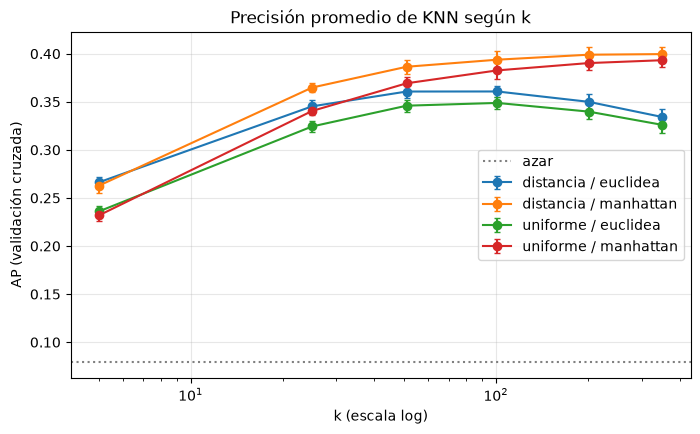

Elegido: {'k': 351, 'pesos': 'distancia', 'metrica': 'manhattan'} | AP = 0.3996


In [12]:
grilla = {
    "knn__k": [5, 25, 51, 101, 201, 351],
    "knn__pesos": ["uniforme", "distancia"],
    "knn__metrica": ["euclidea", "manhattan"],   # equivale a p = 2 y p = 1 de Minkowski
}
busqueda = GridSearchCV(armar_knn(), grilla, cv=CV, scoring="average_precision", n_jobs=2, refit=False)
busqueda.fit(X_train, y_train)

cv_res = pd.DataFrame(busqueda.cv_results_)
cv_res["k"] = cv_res["param_knn__k"]
cv_res["pesos"] = cv_res["param_knn__pesos"]
cv_res["metrica"] = cv_res["param_knn__metrica"]
print("Mejores combinaciones:")
display(cv_res.sort_values("mean_test_score", ascending=False)
        [["k", "pesos", "metrica", "mean_test_score", "std_test_score"]].head(8).round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for (pesos, metrica), g in cv_res.groupby(["pesos", "metrica"]):
    g = g.sort_values("k")
    ax.errorbar(g["k"].astype(int), g["mean_test_score"], yerr=g["std_test_score"] / np.sqrt(5),
                marker="o", capsize=2, label=f"{pesos} / {metrica}")
ax.axhline(y_train.mean(), color="gray", ls=":", label="azar")
ax.set_xscale("log"); ax.set_xlabel("k (escala log)"); ax.set_ylabel("AP (validación cruzada)")
ax.set_title("Precisión promedio de KNN según k"); ax.legend(); ax.grid(alpha=.3)
plt.show()

mejor = cv_res.sort_values("mean_test_score", ascending=False).iloc[0]
PARAMS_KNN = dict(k=int(mejor["k"]), pesos=mejor["pesos"], metrica=mejor["metrica"])
print("Elegido:", PARAMS_KNN, "| AP =", round(mejor["mean_test_score"], 4))

 Las 8 mejores combinaciones usan distancia **manhattan** y el AP mejora al aumentar k hasta estabilizarse alrededor de k = 200-350. Se elige **k = 351, pesos por distancia, manhattan (AP = 0,400)**. Hay que decir que 351 es el borde de la grilla y que la diferencia con k = 201 (0,3990 contra 0,3996) es menor al error estándar (~0,007), así que en la práctica da lo mismo. Un k grande tiene sentido aquí: la tasa de baja es baja (8%) y con pocos vecinos casi nunca aparece más de un positivo, por lo que las probabilidades son ruidosas. Manhattan funciona mejor probablemente porque pesa menos las diferencias grandes en una sola variable.

**Paso 11.** AP sin las variables de permanencia y, por separado, sin `edad_titular`, `dispositivos_promedio` ni `dia_vencimiento`. Conclusión.

In [13]:
base_ap, _ = ap_cv(armar_knn(**PARAMS_KNN))
ap_sin_perm, _ = ap_cv(armar_knn(excluir=VARS_PERMANENCIA, **PARAMS_KNN))
ap_sin_ruido, _ = ap_cv(armar_knn(excluir=VARS_RUIDO, **PARAMS_KNN))

tabla11 = pd.DataFrame({
    "variables": ["todas", "sin permanencia", "sin edad, dispositivos y dia_vencimiento"],
    "AP": [base_ap, ap_sin_perm, ap_sin_ruido],
})
tabla11["diferencia vs todas"] = tabla11["AP"] - base_ap
display(tabla11.round(4))

,variables,AP,diferencia vs todas
0,todas,0.3996,0.0000
1,sin permanencia,0.3460,-0.0536
2,"sin edad, dispositivos y dia_vencimiento",0.4037,0.0041


**Conclusión.** Quitar las variables de **permanencia** baja el AP en 0,054 (de 0,400 a 0,346): aportan información real. Quitar `edad_titular`, `dispositivos_promedio` y `dia_vencimiento` **no empeora** el modelo (0,404, la diferencia de +0,004 está dentro del ruido): son variables sin señal que solo agregan ruido a las distancias. Esto se debe a que KNN trata todas las variables como igualmente importantes. Se mantiene el conjunto completo por consistencia con el resto del análisis, aunque eliminarlas sería razonable.

## Parte D · Naive Bayes gaussiano como comparación

**Paso 12.** AP de `GaussianNB` con el mismo preprocesamiento, con y sin transformación logarítmica.

In [14]:
from sklearn.naive_bayes import GaussianNB

ap_nb_log, _ = ap_cv(Pipeline([("prep", construir_preprocesador(log=True)), ("nb", GaussianNB())]))
ap_nb_sin_log, _ = ap_cv(Pipeline([("prep", construir_preprocesador(log=False)), ("nb", GaussianNB())]))
print(f"AP GaussianNB con log1p:  {ap_nb_log:.4f}")
print(f"AP GaussianNB sin log1p:  {ap_nb_sin_log:.4f}")
print(f"(AP KNN elegido:          {base_ap:.4f})")

AP GaussianNB con log1p:  0.3515
AP GaussianNB sin log1p:  0.3210
(AP KNN elegido:          0.3996)


 Naive Bayes llega a 0,352 con `log1p` y 0,321 sin ella: la transformación ayuda porque `uso_mensual_gb` y `horas_sin_servicio_90d` son muy asimétricas y se parecen más a una normal después del logaritmo. Aun así, queda por debajo del KNN (0,400).

**Paso 13.** Correlación de Spearman entre las variables de calidad del servicio y relación con el supuesto de independencia.

,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.233,-0.359,-0.282
horas_sin_servicio_90d,-0.233,1.000,0.290,0.097
reclamos_tecnicos_90d,-0.359,0.290,1.000,0.155
visitas_tecnicas_12m,-0.282,0.097,0.155,1.000


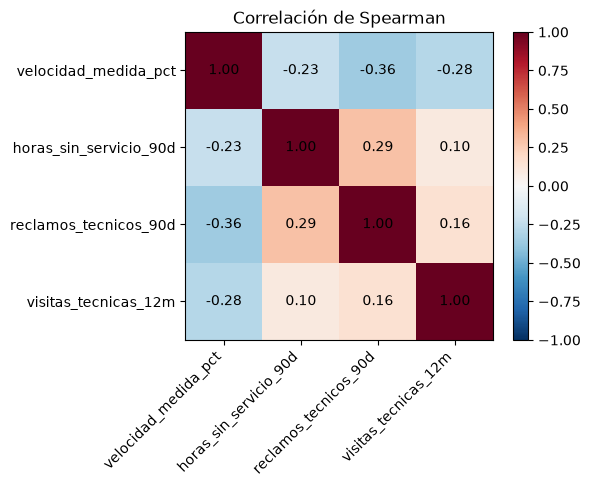

In [15]:
calidad = ["velocidad_medida_pct", "horas_sin_servicio_90d", "reclamos_tecnicos_90d", "visitas_tecnicas_12m"]
rho = res[calidad].corr(method="spearman")
display(rho.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(calidad))); ax.set_xticklabels(calidad, rotation=45, ha="right")
ax.set_yticks(range(len(calidad))); ax.set_yticklabels(calidad)
for i in range(len(calidad)):
    for j in range(len(calidad)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im); ax.set_title("Correlación de Spearman"); plt.show()

 Las variables de calidad están correlacionadas de forma moderada: velocidad y reclamos (ρ = −0,36), velocidad y visitas (−0,28), horas sin servicio y reclamos (0,29). Naive Bayes supone que, dada la clase, las variables son independientes; acá no lo son, porque un mismo problema técnico se refleja en varias a la vez. 

**Paso 14.** Probabilidades fuera de muestra de los dos modelos: puntaje de Brier e histogramas. ¿Cuál exagera más su confianza?

Brier KNN:                 0.0648
Brier Naive Bayes:         0.1077
Brier de predecir la tasa: 0.0728  (referencia)


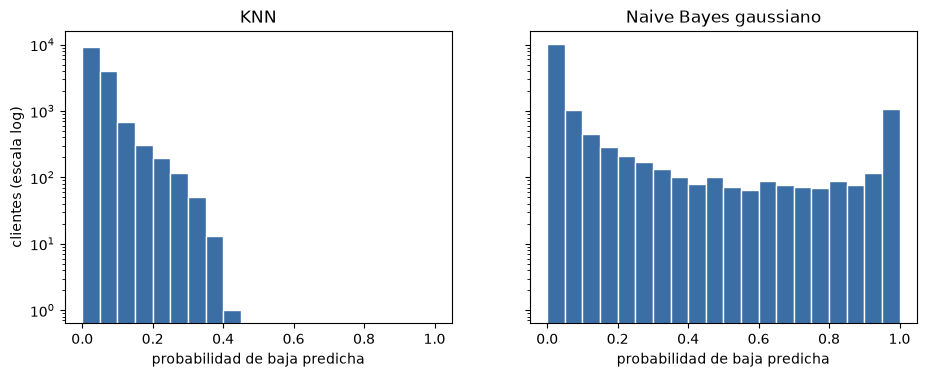

Probabilidades > 0.9 -> KNN: 0 | NB: 1180
Probabilidades < 0.01 -> KNN: 185 | NB: 7363


In [16]:
from sklearn.metrics import brier_score_loss

knn_cv = armar_knn(**PARAMS_KNN)
nb_cv = Pipeline([("prep", construir_preprocesador(log=True)), ("nb", GaussianNB())])
# Probabilidades fuera de muestra (cada cliente se predice con un modelo que no lo vio)
oof_knn = cross_val_predict(knn_cv, X_train, y_train, cv=CV, method="predict_proba", n_jobs=2)[:, 1]
oof_nb = cross_val_predict(nb_cv, X_train, y_train, cv=CV, method="predict_proba", n_jobs=2)[:, 1]

brier_ref = brier_score_loss(y_train, np.full(len(y_train), y_train.mean()))
print(f"Brier KNN:                 {brier_score_loss(y_train, oof_knn):.4f}")
print(f"Brier Naive Bayes:         {brier_score_loss(y_train, oof_nb):.4f}")
print(f"Brier de predecir la tasa: {brier_ref:.4f}  (referencia)")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, p, nombre in zip(ejes, [oof_knn, oof_nb], ["KNN", "Naive Bayes gaussiano"]):
    ax.hist(p, bins=20, range=(0, 1), color="#3b6ea5", edgecolor="white")
    ax.set_yscale("log"); ax.set_title(nombre); ax.set_xlabel("probabilidad de baja predicha")
ejes[0].set_ylabel("clientes (escala log)")
plt.show()
print("Probabilidades > 0.9 -> KNN:", int((oof_knn > .9).sum()), "| NB:", int((oof_nb > .9).sum()))
print("Probabilidades < 0.01 -> KNN:", int((oof_knn < .01).sum()), "| NB:", int((oof_nb < .01).sum()))

 El Brier de KNN (0,0648) mejora el de predecir siempre la tasa de baja (0,0728); el de Naive Bayes (**0,1077**) es *peor* que no usar modelo. Los histogramas lo explican: Naive Bayes asigna probabilidad mayor a 0,9 a 1.180 clientes y menor a 0,01 a 7.363, mientras que KNN no pasa de 0,9 en ningún caso. **Naive Bayes es el que exagera su confianza** (consistente con el paso 13). En cambio, KNN con k = 351 hace lo contrario: promedia muchos vecinos y comprime las probabilidades hacia el centro. Naive Bayes ordena bien a los clientes (AP 0,35) pero sus probabilidades no son confiables.

## Parte E · Economía de la campaña (`src/negocio.py`)

**Paso 15.** Implementen las funciones de `src/negocio.py` hasta que pasen `tests/test_negocio.py`. Informen G⁺, G⁻ y la probabilidad de equilibrio.

In [17]:
!python -m pytest -q tests/test_negocio.py

g_pos, g_neg = resultado_por_contacto(SUPUESTOS)
P_EQ = probabilidad_de_equilibrio(SUPUESTOS)
print(f"G+ (contactar a quien se iba):     Gs. {g_pos:,.0f}")
print(f"G- (contactar a quien se quedaba): Gs. {g_neg:,.0f}")
print(f"Probabilidad de equilibrio:        {P_EQ:.4f}")

.......                                                                  [100%]
7 passed in 0.84s
G+ (contactar a quien se iba):     Gs. 310,000
G- (contactar a quien se quedaba): Gs. -130,000
Probabilidad de equilibrio:        0.2955


 Contactar a un cliente que se iba a ir rinde **G⁺ = Gs. 310.000** (0,4 × (1.000.000 − 200.000) − 10.000) y contactar a uno que se quedaba cuesta **G⁻ = −Gs. 130.000** (−0,6 × 200.000 − 10.000). La **probabilidad de equilibrio es 29,55%**: solo conviene contactar a quien tenga una probabilidad de baja real mayor a ese valor. Pasan las 7 pruebas de `test_negocio.py`.

**Paso 16.** Regla comercial sobre el conjunto de entrenamiento: clientes marcados, proporción que se fue y ganancia por cada 1.000 clientes.

In [18]:
# Regla del gerente comercial: llamar a los clientes con contrato mensual y 2 o más reclamos técnicos
def regla_comercial(df):
    return ((df["tipo_contrato"] == "mensual") & (df["reclamos_tecnicos_90d"] >= 2)).to_numpy()


regla_train = regla_comercial(res_train)
marcados = int(regla_train.sum())
prop_se_fue = y_train[regla_train].mean()
gan_regla = ganancia_campania(y_train, regla_train)
print(f"Clientes marcados: {marcados} ({marcados / len(y_train):.1%} del entrenamiento)")
print(f"Proporción que se fue: {prop_se_fue:.3f} (tasa general: {y_train.mean():.3f})")
print(f"Ganancia total: Gs. {gan_regla:,.0f}")
print(f"Ganancia por cada 1.000 clientes de la base: Gs. {gan_regla / len(y_train) * 1000:,.0f}")

Clientes marcados: 941 (6.5% del entrenamiento)
Proporción que se fue: 0.227 (tasa general: 0.079)
Ganancia total: Gs. -28,170,000
Ganancia por cada 1.000 clientes de la base: Gs. -1,937,281


 La regla del gerente marca 941 clientes (6,5% del entrenamiento), de los cuales **se fue el 22,7%**: es casi 3 veces la tasa general (7,9%), pero queda por debajo del 29,55% de equilibrio. Por eso la campaña con esta regla **pierde Gs. 28,2 millones** en el entrenamiento (−Gs. 1.937.281 por cada 1.000 clientes de la base): detecta riesgo, pero no lo suficiente para que el descuento se pague solo.

**Paso 17.** Umbral de cada modelo con `mejor_umbral` sobre probabilidades fuera de muestra, con un máximo del 7% de los clientes. Comparación con la probabilidad de equilibrio.

In [19]:
CAP_FRAC = 0.07
cap_train = int(CAP_FRAC * len(y_train))
umbral_knn = mejor_umbral(y_train, oof_knn, max_contactos=cap_train)
umbral_nb = mejor_umbral(y_train, oof_nb, max_contactos=cap_train)

tabla17 = pd.DataFrame({"KNN": umbral_knn, "Naive Bayes": umbral_nb}).T
tabla17["ganancia por 1.000 clientes"] = tabla17["ganancia"] / len(y_train) * 1000
display(tabla17)
print(f"Máximo de contactos permitido: {cap_train} (7% de {len(y_train)})")
print(f"Probabilidad de equilibrio: {P_EQ:.4f}")
for nombre, r in [("KNN", umbral_knn), ("Naive Bayes", umbral_nb)]:
    print(f"Umbral {nombre} = {r['umbral']:.4f}  ->  {'MENOR' if r['umbral'] < P_EQ else 'MAYOR'} que la probabilidad de equilibrio")

# ¿Y sin límite de capacidad?
print("\nSin límite de contactos:", {n: mejor_umbral(y_train, p) for n, p in [("KNN", oof_knn), ("NB", oof_nb)]})

,umbral,ganancia,contactados,ganancia por 1.000 clientes
KNN,0.146079,77980000.0,710.0,5.362767e+06
Naive Bayes,0.996433,59690000.0,783.0,4.104945e+06


Máximo de contactos permitido: 1017 (7% de 14541)
Probabilidad de equilibrio: 0.2955
Umbral KNN = 0.1461  ->  MENOR que la probabilidad de equilibrio
Umbral Naive Bayes = 0.9964  ->  MAYOR que la probabilidad de equilibrio

Sin límite de contactos: {'KNN': {'umbral': 0.14607860112821416, 'ganancia': 77980000.0, 'contactados': 710}, 'NB': {'umbral': 0.9964331618649751, 'ganancia': 59690000.0, 'contactados': 783}}




**Comparación con la probabilidad de equilibrio (0,2955):** el umbral de KNN es *menor* y el de Naive Bayes es *mayor*, y esas diferencias son justamente la mala calibración que vimos en el paso 14. Las probabilidades de KNN están comprimidas (un cliente con 0,15 en realidad tiene un riesgo mucho mayor), y las de Naive Bayes están infladas (para tener un riesgo real razonable hay que pedir 0,996).

**Paso 18.** Evaluación única en prueba: tabla de estrategias y curva de ganancia acumulada.

,contactados,proporción que se iba,ganancia (Gs.),ganancia por 1.000 clientes
estrategia,,,,
No contactar a nadie,0,NaN,0.0,0.0
Contactar a todos,4847,0.079,-461590000.0,-95232102.0
Regla comercial (mensual y ≥2 reclamos),324,0.222,-10440000.0,-2153910.0
KNN con umbral elegido,255,0.522,25370000.0,5234165.0
Naive Bayes con umbral elegido,257,0.475,20270000.0,4181968.0
"Azar (339 clientes, esperado)",339,0.079,-32283683.0,-6660549.0


Lift en el 7% de mayor riesgo: {'KNN': 5.9, 'Naive Bayes': 5.15}


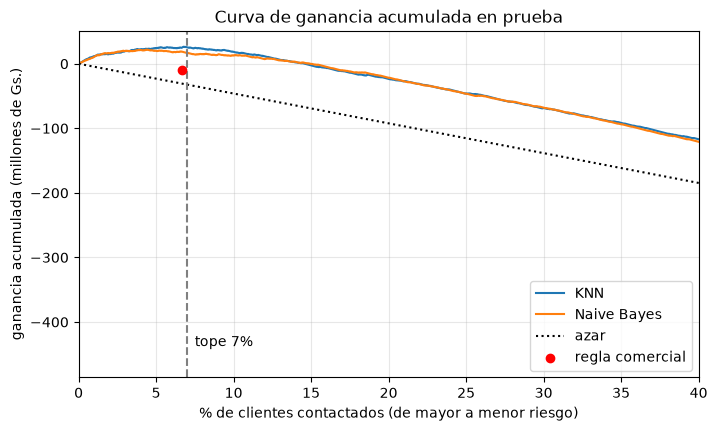

In [20]:
# Se ajustan los modelos con TODO el entrenamiento y se evalúa UNA sola vez en prueba
knn_final_train = armar_knn(**PARAMS_KNN).fit(X_train, y_train)
nb_final_train = Pipeline([("prep", construir_preprocesador(log=True)), ("nb", GaussianNB())]).fit(X_train, y_train)
p_test = {"KNN": knn_final_train.predict_proba(X_test)[:, 1], "Naive Bayes": nb_final_train.predict_proba(X_test)[:, 1]}

n_test = len(y_test)
cap_test = int(CAP_FRAC * n_test)


def marcar(prob, umbral, cap):
    m = prob >= umbral
    if m.sum() > cap:                      # respeta la capacidad: los de mayor probabilidad
        m = np.zeros(len(prob), dtype=bool)
        m[np.argsort(-prob, kind="stable")[:cap]] = True
    return m


regla_test = regla_comercial(res_test)
estrategias = {
    "No contactar a nadie": np.zeros(n_test, dtype=bool),
    "Contactar a todos": np.ones(n_test, dtype=bool),
    "Regla comercial (mensual y ≥2 reclamos)": regla_test,
    "KNN con umbral elegido": marcar(p_test["KNN"], umbral_knn["umbral"], cap_test),
    "Naive Bayes con umbral elegido": marcar(p_test["Naive Bayes"], umbral_nb["umbral"], cap_test),
}
filas = []
for nombre, m in estrategias.items():
    n = int(m.sum())
    filas.append({"estrategia": nombre, "contactados": n,
                  "proporción que se iba": y_test[m].mean() if n else np.nan,
                  "ganancia (Gs.)": ganancia_campania(y_test, m),
                  "ganancia por 1.000 clientes": ganancia_campania(y_test, m) / n_test * 1000})
# Referencia: contactar al azar a la misma cantidad que el máximo permitido (valor esperado)
g_pos, g_neg = resultado_por_contacto()
azar = cap_test * (y_test.mean() * g_pos + (1 - y_test.mean()) * g_neg)
filas.append({"estrategia": f"Azar ({cap_test} clientes, esperado)", "contactados": cap_test,
              "proporción que se iba": y_test.mean(), "ganancia (Gs.)": azar,
              "ganancia por 1.000 clientes": azar / n_test * 1000})
tabla18 = pd.DataFrame(filas).set_index("estrategia")
display(tabla18.round({"proporción que se iba": 3, "ganancia (Gs.)": 0, "ganancia por 1.000 clientes": 0}))
print("Lift en el 7% de mayor riesgo:", {n: round(lift(y_test, p, CAP_FRAC), 2) for n, p in p_test.items()})

# Curva de ganancia acumulada
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, p in p_test.items():
    orden = np.argsort(-p, kind="stable")
    g = np.cumsum(np.where(y_test[orden] == 1, g_pos, g_neg))
    ax.plot(np.arange(1, n_test + 1) / n_test * 100, g / 1e6, label=nombre)
x = np.array([0, 100])
ax.plot(x, [0, n_test * (y_test.mean() * g_pos + (1 - y_test.mean()) * g_neg) / 1e6], "k:", label="azar")
ax.scatter([regla_test.mean() * 100], [ganancia_campania(y_test, regla_test) / 1e6], color="red", zorder=5, label="regla comercial")
ax.axvline(CAP_FRAC * 100, color="gray", ls="--"); ax.text(CAP_FRAC * 100 + .5, ax.get_ylim()[0] * .9, "tope 7%")
ax.set_xlim(0, 40); ax.set_xlabel("% de clientes contactados (de mayor a menor riesgo)")
ax.set_ylabel("ganancia acumulada (millones de Gs.)"); ax.set_title("Curva de ganancia acumulada en prueba")
ax.legend(); ax.grid(alpha=.3); plt.show()

**Lectura (evaluación única en prueba).** El modelo KNN gana **Gs. 25,4 millones** contactando a 255 clientes, de los cuales se iba el 52,2%. Naive Bayes gana 20,3 millones con 257 contactos (47,5% acertados). La **regla del gerente pierde Gs. 10,4 millones**: contacta a 324 clientes y solo se iba el 22,2%, por debajo del 29,55% de equilibrio (igual que en el entrenamiento). Contactar al azar o a todos también pierde dinero (−Gs. 461,6 millones si se contacta a todos). El *lift* en el 7% de mayor riesgo es 5,9 para KNN y 5,2 para Naive Bayes: el 7% más riesgoso de KNN se va casi 6 veces más que el cliente promedio. La curva de ganancia acumulada muestra que KNN domina a Naive Bayes y que la ganancia se alcanza con pocos contactos y luego decrece al incluir clientes de bajo riesgo.

## Parte F · Explicación para Fidelización

**Paso 19.** Importancia por permutación del modelo elegido sobre prueba (`average_precision`).

Modelo elegido: KNN


,variable,caida_AP,desvio
11,consulto_baja_web_30d,0.1961,0.0095
15,zona,0.0563,0.0032
3,plan_mbps,0.0207,0.0042
14,sin_permanencia_3m,0.0192,0.0057
5,cargo_mensual_gs,0.0180,0.0013
8,reclamos_tecnicos_90d,0.0172,0.0067
7,velocidad_medida_pct,0.0164,0.0088
10,facturas_atrasadas_6m,0.0091,0.0028
16,tipo_contrato,0.0086,0.0027
18,metodo_pago,0.0062,0.0009


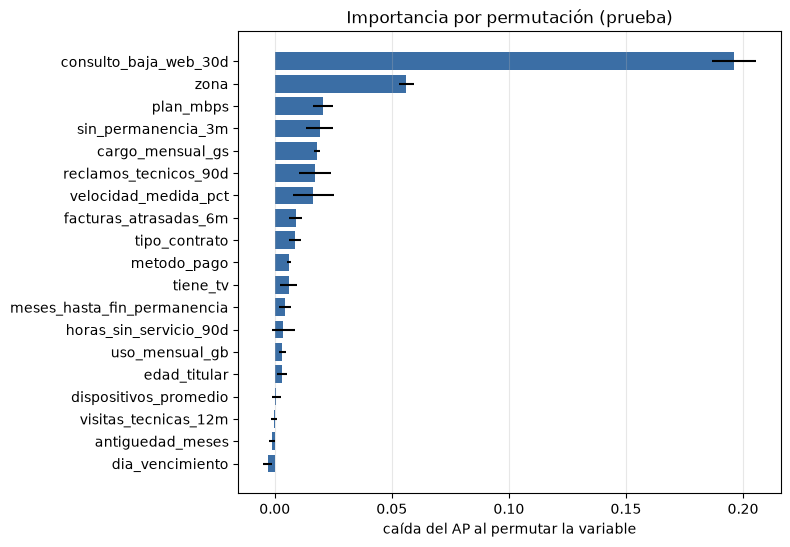

In [21]:
from sklearn.inspection import permutation_importance

# Modelo elegido: el de mayor ganancia (fuera de muestra, en entrenamiento) bajo el tope de 7%
ELEGIDO = "KNN" if umbral_knn["ganancia"] >= umbral_nb["ganancia"] else "Naive Bayes"
modelo_elegido = knn_final_train if ELEGIDO == "KNN" else nb_final_train
print("Modelo elegido:", ELEGIDO)

imp = permutation_importance(modelo_elegido, X_test, y_test, scoring="average_precision",
                             n_repeats=5, random_state=SEMILLA, n_jobs=2)
imp_df = pd.DataFrame({"variable": FEATURES, "caida_AP": imp.importances_mean, "desvio": imp.importances_std}) \
    .sort_values("caida_AP")
display(imp_df.sort_values("caida_AP", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp_df["variable"], imp_df["caida_AP"], xerr=imp_df["desvio"], color="#3b6ea5")
ax.set_xlabel("caída del AP al permutar la variable"); ax.set_title("Importancia por permutación (prueba)")
ax.grid(axis="x", alpha=.3); plt.show()

 Se elige KNN.La variable más importante es **`consulto_baja_web_30d`**, seguida de **`zona`** (0,056), `plan_mbps`, `sin_permanencia_3m`, `cargo_mensual_gs`, `reclamos_tecnicos_90d` y `velocidad_medida_pct` (~0,02 cada una). Las variables de ruido identificadas en el paso 11 (`dia_vencimiento`, `dispositivos_promedio`, `antiguedad_meses`) tienen importancia ≈ 0, e incluso levemente negativa, lo que confirma que no aportan.

**Paso 20.** Función `explicar_cliente(id_cliente)` y su aplicación a los 3 clientes de mayor riesgo de la campaña, con la oferta propuesta para cada uno.

In [22]:
# Para explicar clientes de la campaña se necesita el modelo final (paso 21): se reentrena aquí con
# todos los residenciales del histórico y se aplica a la campaña.
campania_bruta = pd.read_csv("datos/clientes_campania.csv")
campania = agregar_variables(campania_bruta)

res_total = res.reset_index(drop=True)          # el orden de filas coincide con los datos que guarda el KNN
y_total = res_total["baja_90d"].to_numpy()
modelo_final = (armar_knn(**PARAMS_KNN) if ELEGIDO == "KNN"
                else Pipeline([("prep", construir_preprocesador(log=True)), ("nb", GaussianNB())])).fit(res_total[FEATURES], y_total)
campania["prob_baja"] = modelo_final.predict_proba(campania[FEATURES])[:, 1]

# La explicación por vecinos siempre usa el KNN (también si el elegido fuera otro modelo)
knn_explicador = modelo_final if ELEGIDO == "KNN" else armar_knn(**PARAMS_KNN).fit(res_total[FEATURES], y_total)
prep_exp, knn_exp = knn_explicador.named_steps["prep"], knn_explicador.named_steps["knn"]

OFERTAS = {
    "precio": "Descuento en el cargo mensual a cambio de renovar permanencia.",
    "competencia": "Mejora de plan (más Mbps) al mismo precio y renovación de permanencia.",
    "calidad_servicio": "Visita técnica prioritaria sin costo y compensación por las horas sin servicio.",
    "mudanza": "Traslado gratuito del servicio al nuevo domicilio.",
    "otros": "Llamada de un ejecutivo para conocer su situación antes de ofrecer descuentos.",
}
SEÑALES = ["reclamos_tecnicos_90d", "horas_sin_servicio_90d", "velocidad_medida_pct", "consulto_baja_web_30d",
           "facturas_atrasadas_6m", "cargo_mensual_gs", "sin_permanencia_3m", "antiguedad_meses"]


def explicar_cliente(id_cliente, base=campania, n_cercanos=5):
    """Muestra los 5 clientes más parecidos del histórico, por qué se fueron y propone una oferta."""
    fila = base[base["id_cliente"] == id_cliente]
    d, idx = knn_exp.kneighbors(prep_exp.transform(fila[FEATURES]))
    todos = res_total.iloc[idx[0]]                 # los k vecinos que usa el modelo (ordenados por cercanía)
    cercanos = todos.iloc[:n_cercanos].assign(distancia=d[0][:n_cercanos].round(2))
    print(f"Cliente {id_cliente} | probabilidad de baja: {fila['prob_baja'].iloc[0]:.1%} "
          f"| zona {fila['zona'].iloc[0]}, contrato {fila['tipo_contrato'].iloc[0]}, "
          f"cargo Gs. {fila['cargo_mensual_gs'].iloc[0]:,.0f}")
    print(f"  Los {n_cercanos} clientes más parecidos del histórico (motivo_baja se usa solo para describirlos):")
    display(cercanos[["id_cliente", "distancia", "tipo_contrato", "reclamos_tecnicos_90d", "horas_sin_servicio_90d",
                      "velocidad_medida_pct", "consulto_baja_web_30d", "baja_90d", "motivo_baja"]])
    motivos = cercanos.loc[cercanos["baja_90d"] == 1, "motivo_baja"].value_counts()
    origen = f"{n_cercanos} más parecidos"
    if len(motivos) == 0:                            # ninguno de los 5 se fue: se usan todos los vecinos del modelo
        motivos = todos.loc[todos["baja_90d"] == 1, "motivo_baja"].value_counts()
        origen = f"{len(todos)} vecinos del modelo"
    print(f"  Se fueron {int(cercanos['baja_90d'].sum())} de los {n_cercanos}. "
          f"Motivos entre los que se fueron ({origen}): {motivos.to_dict()}")
    comp = pd.DataFrame({"cliente": fila[SEÑALES].iloc[0], "promedio base": res_total[SEÑALES].mean(),
                         f"promedio {n_cercanos} cercanos": cercanos[SEÑALES].mean()}).round(2)
    display(comp)
    motivo = motivos.index[0] if len(motivos) else "otros"
    print(f"  Oferta propuesta ({motivo}): {OFERTAS[motivo]}\n")
    return motivo


top3 = campania[campania["segmento"] == "residencial"].nlargest(3, "prob_baja")["id_cliente"]
for cid in top3:
    explicar_cliente(cid)

Cliente NI-301055 | probabilidad de baja: 44.9% | zona este, contrato mensual, cargo Gs. 448,000
  Los 5 clientes más parecidos del histórico (motivo_baja se usa solo para describirlos):


,id_cliente,distancia,tipo_contrato,reclamos_tecnicos_90d,horas_sin_servicio_90d,velocidad_medida_pct,consulto_baja_web_30d,baja_90d,motivo_baja
113,NI-103284,8.11,mensual,1,11.1,64.9,0,1,competencia
15703,NI-110878,8.50,mensual,1,7.4,85.3,1,1,precio
17267,NI-119536,8.97,mensual,1,0.6,59.5,1,1,mudanza
12988,NI-104349,9.37,mensual,1,6.6,92.5,1,0,NaN
10435,NI-115318,9.73,mensual,1,11.8,82.3,1,1,competencia


  Se fueron 4 de los 5. Motivos entre los que se fueron (5 más parecidos): {'competencia': 2, 'precio': 1, 'mudanza': 1}


,cliente,promedio base,promedio 5 cercanos
reclamos_tecnicos_90d,1.00,0.54,1.00
horas_sin_servicio_90d,9.20,3.83,7.50
velocidad_medida_pct,66.00,88.73,76.90
consulto_baja_web_30d,1.00,0.06,0.80
facturas_atrasadas_6m,2.00,0.43,1.20
cargo_mensual_gs,448000.00,244914.23,403000.00
sin_permanencia_3m,1.00,0.66,1.00
antiguedad_meses,28.78,36.47,34.54


  Oferta propuesta (competencia): Mejora de plan (más Mbps) al mismo precio y renovación de permanencia.

Cliente NI-305479 | probabilidad de baja: 44.3% | zona este, contrato mensual, cargo Gs. 428,000
  Los 5 clientes más parecidos del histórico (motivo_baja se usa solo para describirlos):


,id_cliente,distancia,tipo_contrato,reclamos_tecnicos_90d,horas_sin_servicio_90d,velocidad_medida_pct,consulto_baja_web_30d,baja_90d,motivo_baja
8183,NI-106252,5.88,mensual,1,4.3,55.0,1,1,precio
13031,NI-108791,8.00,12_meses,0,15.5,74.3,1,1,competencia
3098,NI-102205,9.77,mensual,1,0.0,72.1,1,1,competencia
17900,NI-107753,9.88,mensual,0,0.6,85.4,1,1,competencia
10729,NI-115877,9.89,mensual,0,11.6,70.9,1,1,precio


... (3 outputs left out)

,id_cliente,distancia,tipo_contrato,reclamos_tecnicos_90d,horas_sin_servicio_90d,velocidad_medida_pct,consulto_baja_web_30d,baja_90d,motivo_baja
10456,NI-102398,6.87,mensual,1,0.0,62.4,1,1,competencia
6551,NI-105247,7.24,mensual,0,0.0,63.4,1,1,precio
3098,NI-102205,7.44,mensual,1,0.0,72.1,1,1,competencia
5293,NI-109037,7.92,mensual,1,0.0,55.1,0,1,competencia
18230,NI-105432,8.33,mensual,1,0.0,87.4,1,1,calidad_servicio


  Se fueron 5 de los 5. Motivos entre los que se fueron (5 más parecidos): {'competencia': 3, 'precio': 1, 'calidad_servicio': 1}


,cliente,promedio base,promedio 5 cercanos
reclamos_tecnicos_90d,1.00,0.54,0.80
horas_sin_servicio_90d,0.00,3.83,0.00
velocidad_medida_pct,64.40,88.73,68.08
consulto_baja_web_30d,1.00,0.06,0.80
facturas_atrasadas_6m,0.00,0.43,0.20
cargo_mensual_gs,379000.00,244914.23,411600.00
sin_permanencia_3m,1.00,0.66,1.00
antiguedad_meses,73.42,36.47,61.71


  Oferta propuesta (competencia): Mejora de plan (más Mbps) al mismo precio y renovación de permanencia.



 Para cada uno de los 3 clientes de mayor riesgo de la campaña, `explicar_cliente` muestra su probabilidad de baja, los **5 clientes más parecidos** del histórico (si se fueron y por qué), la comparación de sus señales con el promedio de la base y la oferta propuesta según el motivo más frecuente entre los parecidos que se fueron (precio, competencia, calidad de servicio, mudanza u otros). Si ninguno de los 5 se fue, se usan los vecinos del modelo para elegir el motivo. Conviene leer las señales propias del cliente (horas sin servicio, velocidad medida, reclamos) para ajustar la oferta: por ejemplo, un cliente con muchas horas sin servicio merece una visita técnica antes que un descuento.

*Nota de uso de `motivo_baja`:* se usa solo para describir a los vecinos que ya se fueron, nunca como variable del modelo.

## Parte G · Lista de la campaña de octubre

**Paso 21.** Reentrenen el modelo con todos los clientes residenciales del histórico y calculen la probabilidad de baja de `datos/clientes_campania.csv`.

In [23]:
# El modelo final (ver paso 20) está entrenado con todos los residenciales del histórico
print(f"Modelo final: {ELEGIDO} entrenado con {len(res_total)} clientes residenciales")
print(f"Clientes de la campaña: {len(campania)} ({(campania['segmento'] == 'empleado').sum()} empleados)")
campania["prob_baja"].describe().round(4)

Modelo final: KNN entrenado con 19388 clientes residenciales
Clientes de la campaña: 6000 (157 empleados)


count    6000.0000
mean        0.0563
std         0.0532
min         0.0000
25%         0.0272
50%         0.0419
75%         0.0633
max         0.4489
Name: prob_baja, dtype: float64

 Con todo el histórico residencial (19.388 clientes) se entrenó el modelo final. Las variables de la campaña se calcularon a su propia `fecha_corte` (30/09/2026). La media de las variables de la campaña es prácticamente idéntica a la del histórico (reclamos 0,54 en ambos, consulta de baja 5,9% en ambos).

**Paso 22.** Generen `campania_octubre.csv` (6.000 filas; columnas `id_cliente`, `prob_baja`, `contactar`) y verifiquen: como máximo 420 contactos, ningún empleado, ningún cliente repetido.

In [24]:
CAP_CAMP = int(CAP_FRAC * len(campania))          # 420
es_res = (campania["segmento"] == "residencial").to_numpy()
prob_elegible = np.where(es_res, campania["prob_baja"].to_numpy(), -1.0)    # los empleados nunca se contactan
elegido_mask = prob_elegible >= (umbral_knn if ELEGIDO == "KNN" else umbral_nb)["umbral"]
if elegido_mask.sum() > CAP_CAMP:
    elegido_mask = np.zeros(len(campania), dtype=bool)
    elegido_mask[np.argsort(-prob_elegible, kind="stable")[:CAP_CAMP]] = True

salida = pd.DataFrame({"id_cliente": campania["id_cliente"], "prob_baja": campania["prob_baja"].round(6),
                       "contactar": elegido_mask.astype(int)})
salida.to_csv("campania_octubre.csv", index=False)

# Verificaciones
assert len(salida) == 6000
assert salida["contactar"].sum() <= 420
assert salida.loc[campania["segmento"] == "empleado", "contactar"].sum() == 0
assert salida["id_cliente"].is_unique
print("Verificaciones OK -> filas:", len(salida), "| contactos:", int(salida["contactar"].sum()),
      "| empleados contactados: 0 | repetidos: 0")
salida.sort_values("prob_baja", ascending=False).head()

Verificaciones OK -> filas: 6000 | contactos: 331 | empleados contactados: 0 | repetidos: 0


,id_cliente,prob_baja,contactar
1773,NI-301055,0.448940,1
3397,NI-305479,0.442671,1
5591,NI-305687,0.418340,1
5467,NI-304391,0.414078,1
4784,NI-304280,0.412559,1


 El archivo `campania_octubre.csv` tiene 6.000 filas y **331 contactos**: son los clientes residenciales con probabilidad mayor o igual al umbral de 0,146, y no llegan al tope de 420 porque el resto no cumple el umbral. Las verificaciones pasan: no supera 420, no hay empleados contactados y no hay clientes repetidos.

**Paso 23.** Ganancia esperada de la campaña con la precisión observada en prueba.

In [25]:
# Precisión observada en prueba para la estrategia del modelo elegido (proporción de contactados que se iba)
m_test = estrategias["KNN con umbral elegido" if ELEGIDO == "KNN" else "Naive Bayes con umbral elegido"]
precision_test = y_test[m_test].mean()
n_contactos = int(salida["contactar"].sum())
g_pos, g_neg = resultado_por_contacto()
ganancia_esperada = n_contactos * (precision_test * g_pos + (1 - precision_test) * g_neg)

print(f"Precisión observada en prueba: {precision_test:.3f}")
print(f"Contactos de la campaña: {n_contactos}")
print(f"Ganancia esperada: {n_contactos} x ({precision_test:.3f} x {g_pos:,.0f} + {1 - precision_test:.3f} x {g_neg:,.0f})"
      f" = Gs. {ganancia_esperada:,.0f}")
# Sensibilidad: la precisión de prueba es una estimación con ruido (n pequeño)
n_t = int(m_test.sum())
ee = np.sqrt(precision_test * (1 - precision_test) / n_t)
for etiqueta, p in [("pesimista (-1 e.e.)", precision_test - ee), ("observada", precision_test), ("optimista (+1 e.e.)", precision_test + ee)]:
    print(f"  {etiqueta:22s} precisión {p:.3f} -> Gs. {n_contactos * (p * g_pos + (1 - p) * g_neg):,.0f}")

Precisión observada en prueba: 0.522
Contactos de la campaña: 331
Ganancia esperada: 331 x (0.522 x 310,000 + 0.478 x -130,000) = Gs. 32,931,255
  pesimista (-1 e.e.)    precisión 0.490 -> Gs. 28,375,334
  observada              precisión 0.522 -> Gs. 32,931,255
  optimista (+1 e.e.)    precisión 0.553 -> Gs. 37,487,175


 Con la precisión observada en la prueba (52,2%), los 331 contactos generarían una ganancia esperada de **~Gs. 32,9 millones**. Como la precisión se midió con solo 255 contactos, tiene un error estándar de ±3,1 puntos, que lleva el rango a **Gs. 28 a 37 millones**. Es una estimación optimista en un sentido: supone que el desempeño de mayo se mantiene en septiembre y que las tasas de aceptación del descuento (40% / 60%) son las supuestas.

## Parte H · Informe ejecutivo

**Paso 24.** El informe para Martín Aquino se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. `motivo_baja` no puede ser variable del modelo, pero sí se usó para explicar a los vecinos. ¿Por qué un uso es incorrecto y el otro no?**

_Respuesta:_ Usar motivo_baja como variable es incorrecto porque solo existe después del evento que queremos predecir, usarlo para explicar a los vecinos es correcto porque es un uso descriptivo y posterior: la probabilidad ya se calculó sin esa columna, y luego se miran los vecinos parecidos que ya se fueron para entender por qué y adaptar la oferta.

**2. ¿Por qué KNN necesita estandarizar las variables y Naive Bayes gaussiano no?**

_Respuesta:_ Porque KNN decide quiénes son los vecinos con una distancia que suma las diferencias de todas las variables en sus unidades originales, por lo que las variables con escalas grandes dominan y las demás casi no influyen. Naive Bayes gaussiano, en cambio, modela cada variable por separado dentro de cada clase, con su propia media y desvío, y nunca compara variables entre sí. 

**3. ¿Qué dice la diferencia entre el umbral elegido y la probabilidad de equilibrio sobre las probabilidades de KNN? ¿Qué le responderían a Finanzas?**

_Respuesta:_ El umbral elegido para KNN (0,146) es casi la mitad de la probabilidad de equilibrio (0,2955), lo que indica que las probabilidades de KNN están subestimadas. A Finanzas le respondería que el 29,55% es correcto, pero se aplica a la probabilidad real y no a la salida cruda de KNN, que no está calibrada. Aplicar 0,2955 directamente sobre esa salida llevaría a contactar a muy pocos clientes y a perder ganancia

**4. ¿Cómo medirían el efecto real de la campaña de octubre?**

_Respuesta:_ 

**5. ¿Es aceptable ofrecer descuentos solo a algunos clientes según su zona o su perfil? ¿Qué riesgos ven?**

_Respuesta:_ Es aceptable si el criterio está ligado al comportamiento o al riesgo comercial (por ejemplo reclamos o consulta de baja) y se aplica igual a todos los clientes con el mismo perfil, pero tiene riesgos. Hay un riesgo de equidad y de reputación: si dos vecinos pagan precios distintos por el mismo servicio, se percibe como discriminación, y la zona puede funcionar como sustituto de nivel de ingresos u otras características sensibles.

**6. ¿Qué implica que KNN guarde los datos de entrenamiento para actualizar el modelo y para la privacidad?**

_Respuesta:_ En KNN el modelo es el conjunto de datos de entrenamiento: no aprende parámetros, solo guarda los datos y busca vecinos en ellos al predecir. Para actualizarlo es ventajoso, porque alcanza con agregar clientes nuevos con su resultado, sin reentrenar, pero cada predicción es más lenta a medida que crece la base, porque hay que calcular la distancia contra todos los clientes guardados

**7. ¿Qué pudo cambiar entre la foto de mayo y la de septiembre y cómo lo detectarían antes de lanzar la campaña?**

_Respuesta:_ Pudieron cambiar la estacionalidad (verano, vacaciones y mudanzas de fin de año), las ofertas de la competencia, los precios, el perfil de los clientes nuevos o los vencimientos de contratos, que alteran la distribución de permanencias. Se lo puede detectar comparando la distribución de cada variable entre la foto de mayo y la de septiembre